In [1]:
import sys
print(sys.executable)

/Users/bhavingaikwad/Documents/DS_project/cryptograph-v3/.venv/bin/python


In [2]:
import sys
sys.path.append("../src")

import pandas as pd
import matplotlib.pyplot as plt
from ingestion.load_elliptic import load_raw

features, classes, edgelist = load_raw()
print(features.shape, classes.shape, edgelist.shape)

(203769, 167) (203769, 2) (234355, 2)


In [3]:
classes.columns = ["txId", "label"]
df = features.merge(classes, on="txId", how="left")

label_map = {"1": "illicit", "2": "licit", "unknown": "unknown"}
df["label"] = df["label"].astype(str).map(label_map)

print(df["label"].value_counts())
print(df["label"].value_counts(normalize=True).round(4))

label
unknown    157205
licit       42019
illicit      4545
Name: count, dtype: int64
label
unknown    0.7715
licit      0.2062
illicit    0.0223
Name: proportion, dtype: float64


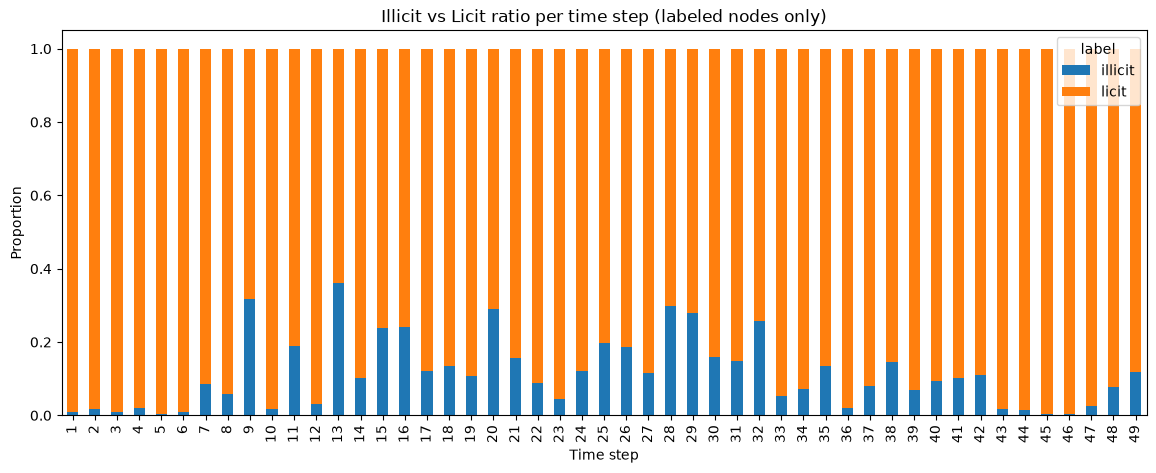

label       illicit     licit
time_step                    
1          0.007918  0.992082
2          0.016115  0.983885
3          0.008600  0.991400
4          0.020833  0.979167
5          0.004251  0.995749
6          0.010309  0.989691
7          0.084788  0.915212
8          0.057511  0.942489
9          0.318766  0.681234
10         0.018519  0.981481
11         0.188218  0.811782
12         0.031621  0.968379
13         0.359703  0.640297
14         0.103118  0.896882
15         0.237864  0.762136
16         0.241509  0.758491
17         0.122072  0.877928
18         0.133676  0.866324
19         0.107383  0.892617
20         0.288889  0.711111
21         0.156006  0.843994
22         0.089620  0.910380
23         0.044650  0.955350
24         0.121670  0.878330
25         0.198653  0.801347
26         0.185687  0.814313
27         0.116505  0.883495
28         0.299296  0.700704
29         0.280239  0.719761
30         0.158397  0.841603
31         0.149296  0.850704
32        

In [4]:
labeled = df[df["label"] != "unknown"]

time_dist = labeled.groupby("time_step")["label"].value_counts(normalize=True).unstack()
time_dist.plot(kind="bar", stacked=True, figsize=(14, 5))
plt.title("Illicit vs Licit ratio per time step (labeled nodes only)")
plt.ylabel("Proportion")
plt.xlabel("Time step")
plt.show()

print(time_dist)

In [5]:
train_mask = df["time_step"] <= 34
test_mask = df["time_step"] > 34

train_labeled = df[train_mask & (df["label"] != "unknown")]
test_labeled = df[test_mask & (df["label"] != "unknown")]

print("=== TRAIN (steps 1-34) ===")
print(train_labeled["label"].value_counts())
print(train_labeled["label"].value_counts(normalize=True).round(4))

print("\n=== TEST (steps 35-49) ===")
print(test_labeled["label"].value_counts())
print(test_labeled["label"].value_counts(normalize=True).round(4))

print("\nTotal labeled train:", len(train_labeled), " Total labeled test:", len(test_labeled))

=== TRAIN (steps 1-34) ===
label
licit      26432
illicit     3462
Name: count, dtype: int64
label
licit      0.8842
illicit    0.1158
Name: proportion, dtype: float64

=== TEST (steps 35-49) ===
label
licit      15587
illicit     1083
Name: count, dtype: int64
label
licit      0.935
illicit    0.065
Name: proportion, dtype: float64

Total labeled train: 29894  Total labeled test: 16670
